## Project Sauvabelin: Firewatch Thymio 

Welcome to our Speedy Fire Department, where we aim to keep the natural forests of Vaud safe and fireproof using our helpful Thymio Robot! We gladly present Department 51 below: 

- Soham (Responsible for Code Scaffolding, Map Generation, State Machine)
- Paul (Responsible for Path Planning)
- Remi (Responsible for Pose Estimation)
- Sébastien (Responsible for Local Navigation)

#### 0. Initial Setup

Add logging to be able to filter between logs for debugging and testing versus logging for information during execution.
Setup a `DEBUG` flag that will also help in providing extra visual information on the system, through plots and diagrams and helpful insights. 

In [1]:
import sys
from loguru import logger

DEBUG = True

logger.remove()
logger.add(sys.stderr, level="DEBUG" if DEBUG else "INFO")

1

#### 1. Map Generation


2026-11-24 18:30:53.108 +01:00 | DEBUG    | map_generation:generate:374 - [(495.0, 133.0), (979.0, 134.0), (977.0, 937.0), (497.0, 933.0)]
2026-11-24 18:30:53.112 +01:00 | INFO     | map_generation:_detect_obstacles:185 - Obstacle dilation active: 2 cell(s) (+1488 dilated grid cells).Decay Factor = 0.4
2026-11-24 18:30:53.117 +01:00 | ERROR    | map_generation:_detect_start:207 - No Robot Tag found. Resorting to White Blob Filtering


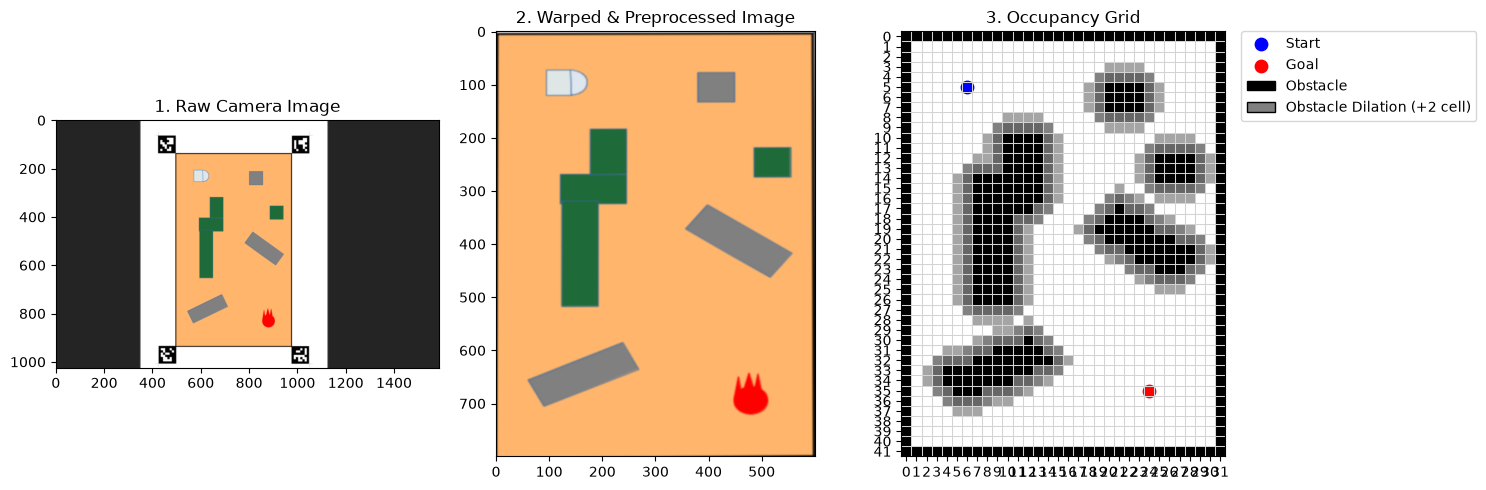

In [2]:
from map_generation import MapGenerator

map_generator = MapGenerator(debug=DEBUG, robot_tag_id=4, map_tag_ids=[0,1,2,3])
# below is offline testing, passing image_path, camera still to be tested
map = map_generator.generate(
    cell_resolution=2, 
    map_width=60, 
    map_height=80, 
    dilation_margin=2, 
    image_path="../assets/map.png")

#### 2a. Path Planning


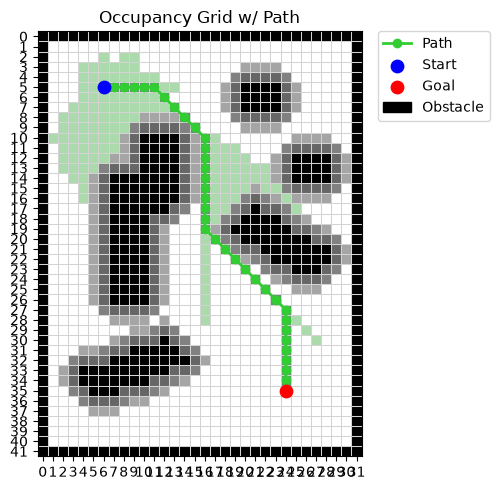

2026-11-24 18:30:58.151 +01:00 | INFO     | path_planning:_line_of_sight_pruning:251 - Original Path Size = 36 Pruned Path Size = 6
2026-11-24 18:30:58.151 +01:00 | INFO     | path_planning:_line_of_sight_pruning:252 - Pruning Duration = 0.0001s
2026-11-24 18:30:58.152 +01:00 | DEBUG    | path_planning:_line_of_sight_pruning:253 - Prunned Path= Path(waypoints=[(5, 6), (7, 13), (10, 16), (19, 16), (28, 24), (35, 24)], cost=42.5)


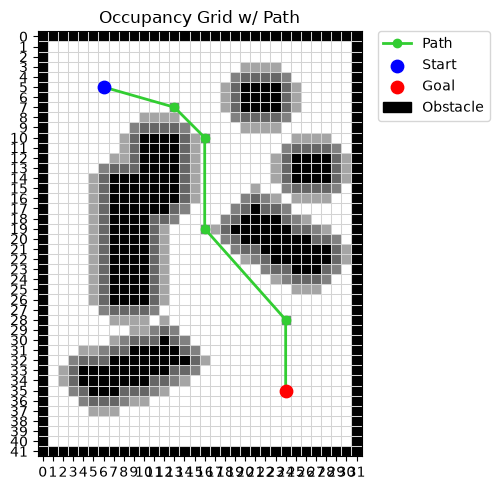

In [3]:
from path_planning import PathPlanner

if map is None:
    logger.info("Map object is None, was not generated correctly.")
    exit(1)

path_planner = PathPlanner(debug=DEBUG)
path, explored, op_count = path_planner.plan(map=map, prune=True, lookahead_distance=7)

In [ ]:
print(path)

#### 2b. Path Planning (Pruning)

#### 3a. Thymio Connection & Sensor/Command Bridge (WIP, needs testing)

Connect to the Thymio via `ClientAsync`, flash an on-robot event listener (`actuate`) to reliably apply motor speeds and top LEDs, and define helper functions to read `SensorData` and dispatch `Command` objects.

In [4]:
import cv2
from tdmclient import ClientAsync
from data_types import Command, SensorData

client = ClientAsync()
node = await client.wait_for_node()
await node.lock()

# Register custom event: [left_speed, right_speed, led_r, led_g, led_b]
await node.register_events([("actuate", 5)])

robot_listener_program = """
onevent actuate
    motor.left.target = event.args[0]
    motor.right.target = event.args[1]
    leds.top = [event.args[2], event.args[3], event.args[4]]
"""
compile_err = await node.compile(robot_listener_program)
if compile_err is not None:
    logger.error(f"Failed to compile Thymio listener program: {compile_err}")
await node.run()

# Wait once for sensor variables to populate on node.v
await node.wait_for_variables({
    "prox.horizontal",
    "prox.ground.delta",
    "motor.left.speed",
    "motor.right.speed",
})
logger.info("Thymio connected and ready.")


def read_sensor_data(node, map_generator: MapGenerator, cam: cv2.VideoCapture, dt: float) -> SensorData:
    """Collect Thymio onboard sensors and overhead camera ArUco pose into SensorData."""
    ok, frame = cam.read()
    pose_from_camera = map_generator.get_robot_state(frame=frame) if ok else None

    return SensorData(
        prox_horizontal=list(node.v.prox.horizontal),
        prox_ground=list(node.v.prox.ground.delta),
        motor_speeds=[
            int(node.v.motor.left.speed),
            int(node.v.motor.right.speed),
        ],
        dt=dt,
        pose_from_camera=pose_from_camera,
    )


async def apply_command(node, cmd: Command) -> None:
    """Convert a Command dataclass into an event sent to the Thymio."""
    r, g, b = cmd.leds_top
    await node.send_events({
        "actuate": [
            int(cmd.motor_left_speed),
            int(cmd.motor_right_speed),
            int(r),
            int(g),
            int(b),
        ]
    })

2026-11-24 18:31:10.871 +01:00 | INFO     | __main__:<module>:30 - Thymio connected and ready.


#### 3b. State Machine Initialization & Real-Time Execution Loop

In [6]:
import time
from data_types import Mode
from local_avoidance import LocalAvoider
from path_following_pid import PIDController
from pose_estimation import PoseEstimator
from state_machine import COMMAND_STOP, StateMachine

LOOP_PERIOD_S = 0.1  # 10 Hz control loop matching Thymio proximity refresh rate

pose_estimator = PoseEstimator(debug=DEBUG)
path_follower = PIDController(debug=DEBUG)
path_follower.setup(path=path)
local_avoider = LocalAvoider(debug=DEBUG)

state_machine = StateMachine(
    map=map,
    map_generator=map_generator,
    path_planner=path_planner,
    pose_estimator=pose_estimator,
    path_follower=path_follower,
    local_avoider=local_avoider,
    debug=DEBUG,
)

cam = cv2.VideoCapture(0)
last_time = time.perf_counter()

try:
    while state_machine.mode not in (Mode.GOAL_REACHED, Mode.ERROR):
        now = time.perf_counter()
        dt = now - last_time
        last_time = now

        sensor_data = read_sensor_data(node, map_generator, cam, dt)
        cmd = state_machine.step(sensor_data)
        await apply_command(node, cmd)

        elapsed = time.perf_counter() - now
        await client.sleep(max(0.01, LOOP_PERIOD_S - elapsed))

    logger.info(f"Control loop finished in mode: {state_machine.mode}")
finally:
    await apply_command(node, COMMAND_STOP)
    cam.release()
    await node.stop()
    await node.unlock()

2026-11-24 18:31:29.523 +01:00 | DEBUG    | pose_estimation:move:62 - Position=State(position=(np.float64(0.0), np.float64(0.0)), heading=0.0)
2026-11-24 18:31:29.524 +01:00 | INFO     | state_machine:step:75 - Robot is Path Following.
2026-11-24 18:31:29.525 +01:00 | DEBUG    | path_following_pid:_state_delta:47 - Current State=State(position=(np.float64(0.0), np.float64(0.0)), heading=0.0) Target Pos=(15.0, 27.0), Target Heading=29.054604099077146
2026-11-24 18:31:29.525 +01:00 | DEBUG    | path_following_pid:_state_delta:54 - Delta Pos=30.886890422961002 Delta Heading=29.054604099077146
2026-11-24 18:31:29.526 +01:00 | INFO     | state_machine:step:116 - [MODE=PATH_FOLLOWING] Following Path, cmd=Command(motor_left_speed=58, motor_right_speed=-58, leds_top=(0, 0, 0))
2026-11-24 18:31:29.740 +01:00 | DEBUG    | pose_estimation:move:62 - Position=State(position=(np.float64(-0.05917154105688283), np.float64(-0.007028756061635251)), heading=6.519649462949441)
2026-11-24 18:31:29.741 +01:

CancelledError: 